PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium_stealth import stealth
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from tqdm import tqdm
tqdm.pandas()  # <- Registers tqdm for pandas
import re

In [27]:
df=pd.read_csv('Data/understat_roster_1524.csv')

In [28]:
df.columns

Index(['id', 'goals', 'own_goals', 'shots', 'xG', 'time', 'player_id',
       'team_id', 'position', 'player', 'h_a', 'yellow_card', 'red_card',
       'roster_in', 'roster_out', 'key_passes', 'assists', 'xA', 'xGChain',
       'xGBuildup', 'positionOrder', 'match_link'],
      dtype='object')

In [29]:
random_match_indexing=df["match_link"]=="https://understat.com/match/81"
df[random_match_indexing]

,id,goals,own_goals,shots,xG,time,player_id,team_id,position,player,...,red_card,roster_in,roster_out,key_passes,assists,xA,xGChain,xGBuildup,positionOrder,match_link
0,620382,0,0,0,0.000000,90,560,89,GK,Sergio Romero,...,0,0,0,0,0,0.000000,0.000000,0.000000,1,https://understat.com/match/81
1,620383,0,0,0,0.000000,82,557,89,DR,Matteo Darmian,...,0,620393,0,1,0,0.106513,0.106513,0.106513,2,https://understat.com/match/81
2,620385,0,0,0,0.000000,90,628,89,DC,Chris Smalling,...,0,0,0,0,0,0.000000,0.106513,0.106513,3,https://understat.com/match/81
3,620384,0,0,0,0.000000,90,548,89,DC,Daley Blind,...,0,0,0,0,0,0.000000,0.127738,0.127738,3,https://understat.com/match/81
4,620386,0,0,0,0.000000,90,1006,89,DL,Luke Shaw,...,0,0,0,0,0,0.000000,0.021225,0.021225,4,https://understat.com/match/81
5,620388,0,0,0,0.000000,61,654,89,DMC,Michael Carrick,...,0,620394,0,1,0,0.035742,0.035742,0.000000,7,https://understat.com/match/81
6,620387,0,0,0,0.000000,90,551,89,DMC,Morgan Schneiderlin,...,0,0,0,0,0,0.000000,0.163670,0.163670,7,https://understat.com/match/81
7,620389,0,0,3,0.253645,90,554,89,AMR,Juan Mata,...,0,0,0,0,0,0.000000,0.255811,0.106513,11,https://understat.com/match/81
8,620390,0,0,3,0.121309,69,555,89,AMC,Memphis Depay,...,0,620395,0,0,0,0.000000,0.056967,0.000000,12,https://understat.com/match/81
9,620391,0,0,1,0.103004,90,631,89,AML,Ashley Young,...,0,0,0,1,0,0.064342,0.124229,0.021225,13,https://understat.com/match/81


In [30]:
# lets create a unique id for each match, by using the match_link
df['understad_match_id'] = df['match_link'].apply(lambda x: x.split('/')[-1]) 

In [31]:
df.head(20).sort_values(by='id')

,id,goals,own_goals,shots,xG,time,player_id,team_id,position,player,...,roster_in,roster_out,key_passes,assists,xA,xGChain,xGBuildup,positionOrder,match_link,understad_match_id
0,620382,0,0,0,0.000000,90,560,89,GK,Sergio Romero,...,0,0,0,0,0.000000,0.000000,0.000000,1,https://understat.com/match/81,81
1,620383,0,0,0,0.000000,82,557,89,DR,Matteo Darmian,...,620393,0,1,0,0.106513,0.106513,0.106513,2,https://understat.com/match/81,81
3,620384,0,0,0,0.000000,90,548,89,DC,Daley Blind,...,0,0,0,0,0.000000,0.127738,0.127738,3,https://understat.com/match/81,81
2,620385,0,0,0,0.000000,90,628,89,DC,Chris Smalling,...,0,0,0,0,0.000000,0.106513,0.106513,3,https://understat.com/match/81,81
4,620386,0,0,0,0.000000,90,1006,89,DL,Luke Shaw,...,0,0,0,0,0.000000,0.021225,0.021225,4,https://understat.com/match/81,81
6,620387,0,0,0,0.000000,90,551,89,DMC,Morgan Schneiderlin,...,0,0,0,0,0.000000,0.163670,0.163670,7,https://understat.com/match/81,81
5,620388,0,0,0,0.000000,61,654,89,DMC,Michael Carrick,...,620394,0,1,0,0.035742,0.035742,0.000000,7,https://understat.com/match/81,81
7,620389,0,0,3,0.253645,90,554,89,AMR,Juan Mata,...,0,0,0,0,0.000000,0.255811,0.106513,11,https://understat.com/match/81,81
8,620390,0,0,3,0.121309,69,555,89,AMC,Memphis Depay,...,620395,0,0,0,0.000000,0.056967,0.000000,12,https://understat.com/match/81,81
9,620391,0,0,1,0.103004,90,631,89,AML,Ashley Young,...,0,0,1,0,0.064342,0.124229,0.021225,13,https://understat.com/match/81,81


In [ ]:
import re

driver = webdriver.Chrome()
driver.get("https://understat.com/match/81")

# Find the link that contains '/league/EPL/' in the href
epl_link = driver.find_element(By.CSS_SELECTOR, "a[href*='league/EPL/']")

# Extract the year using regex
href = epl_link.get_attribute("href")
match = re.search(r"/league/EPL/(\d{4})", href)

if match:
    year = match.group(1)
    print("📅 Extracted Year:", year)
else:
    print("❌ Year not found")

📅 Extracted Year: 2015


In [38]:
def initialize_driver():
    options = webdriver.ChromeOptions()
    options.add_argument('--headless')
    options.add_argument("--start-maximized")


    driver = webdriver.Chrome(options=options)

    stealth(driver,
            languages=["en-US", "en"],
            vendor="Google Inc.",
            platform="Win32",
            webgl_vendor="Intel Inc.",
            renderer="Intel Iris OpenGL Engine",
            fix_hairline=True)
    
    return driver

In [37]:
def get_season(match_url):
    driver = initialize_driver()
    driver.get(match_url)

    try:
        # Wait for the element to be present
        epl_link = WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CSS_SELECTOR, "a[href*='league/EPL/']"))
        )
        
        # Extract the href attribute
        href = epl_link.get_attribute("href")
        
        # Use regex to find the year
        match = re.search(r"/league/EPL/(\d{4})", href)
        
        if match:
            year = match.group(1)
            return year
        else:
            return None
    finally:
        driver.quit()

In [41]:
url_df= pd.DataFrame(df['match_link'].unique(), columns=['match_link'])
url_df['season'] = url_df['match_link'].progress_apply(get_season)

100%|██████████| 3420/3420 [1:14:54<00:00,  1.31s/it]


In [42]:
url_df

,match_link,season
0,https://understat.com/match/81,2015
1,https://understat.com/match/82,2015
2,https://understat.com/match/83,2015
3,https://understat.com/match/84,2015
4,https://understat.com/match/85,2015
...,...,...
3415,https://understat.com/match/22270,2023
3416,https://understat.com/match/22271,2023
3417,https://understat.com/match/22272,2023
3418,https://understat.com/match/22273,2023


In [43]:
url_df.to_csv('Data/understat_season_to_matchlinks.csv', index=False)

In [44]:
df= pd.merge(df, url_df, on='match_link', how='left')

In [49]:
df.columns

Index(['id', 'goals', 'own_goals', 'shots', 'xG', 'time', 'player_id',
       'team_id', 'position', 'player', 'h_a', 'yellow_card', 'red_card',
       'roster_in', 'roster_out', 'key_passes', 'assists', 'xA', 'xGChain',
       'xGBuildup', 'positionOrder', 'match_link', 'understad_match_id',
       'season'],
      dtype='object')

In [51]:
def plot_correlation_matrix(df):
    """
    Plots a correlation matrix for the given DataFrame.
    """
    corr = df.corr()
    corr = corr[(abs(corr) > 0.7)]
    plt.figure(figsize=(18, 13))
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
    plt.title('Correlation Heatmap')
    plt.show()

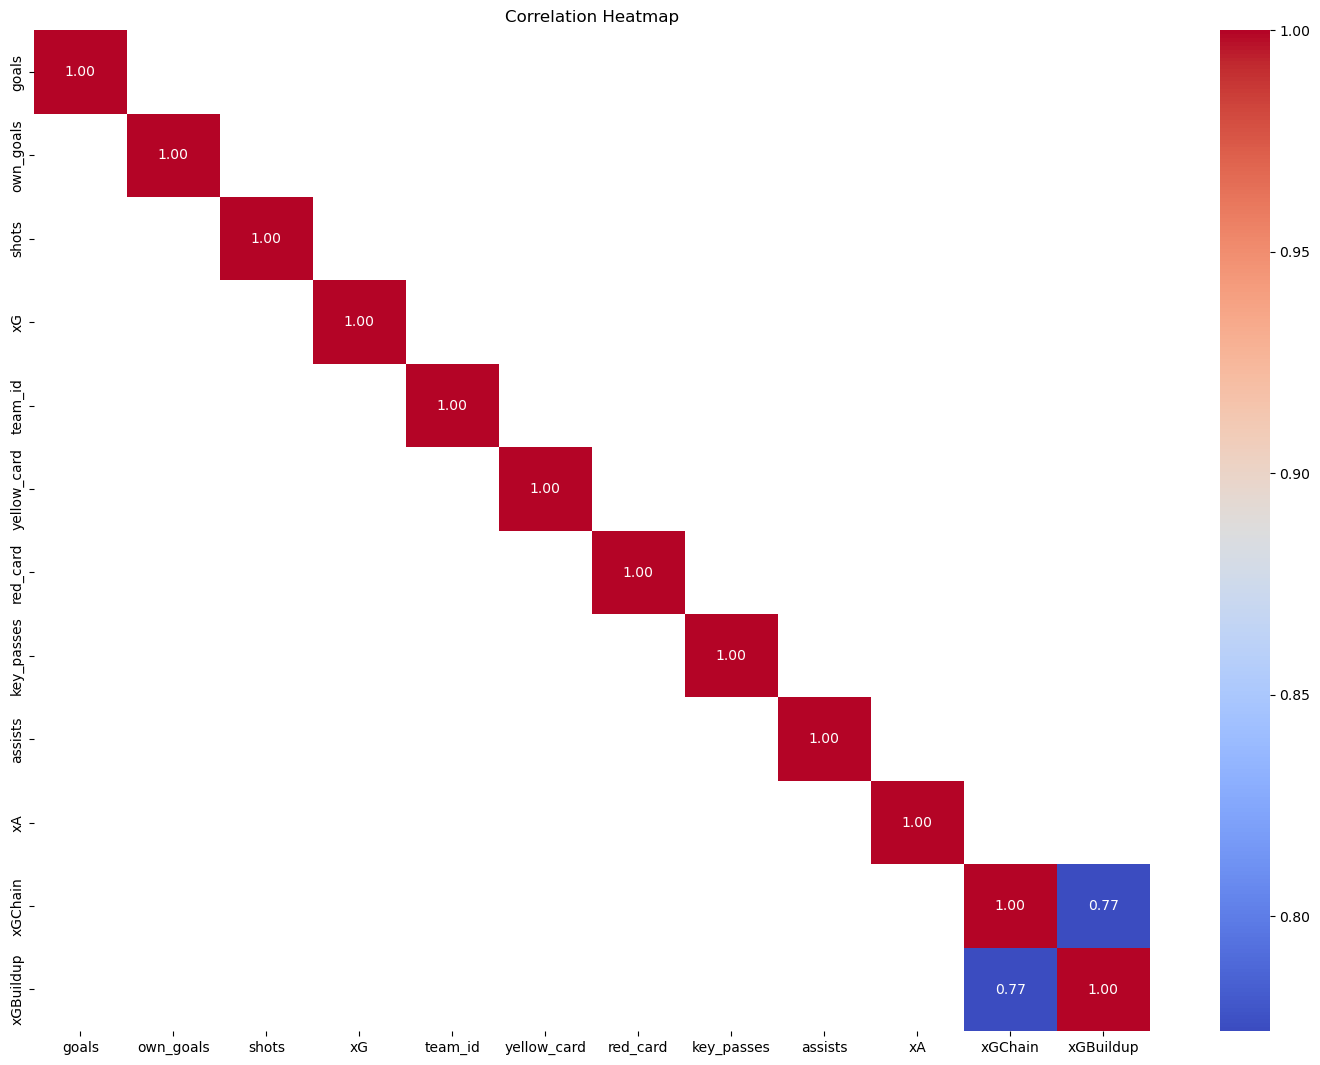

In [58]:
plot_correlation_matrix(df.drop(columns=['id',"player_id","player", 'match_link', 'understad_match_id', 'season', "time", "roster_in", "roster_out", "position","positionOrder","h_a"]))

In [12]:
import io

# Fetching the CSV file from the URL, this URL downloads a CSV file containing ELO ratings for clubs
csv = requests.get("http://api.clubelo.com/2018-04-13")
# Turning it into a pandas DataFrame
df_elo = pd.read_csv(io.StringIO(csv.text))
df_elo.head()

,Rank,Club,Country,Level,Elo,From,To
0,1.0,Barcelona,ESP,1,2032.519531,2018-04-13,2018-04-14
1,2.0,Real Madrid,ESP,1,2014.465698,2018-04-13,2018-04-15
2,3.0,Bayern,GER,1,1977.302734,2018-04-13,2018-04-14
3,4.0,Juventus,ITA,1,1977.041016,2018-04-13,2018-04-15
4,5.0,Man City,ENG,1,1961.221436,2018-04-13,2018-04-14


<Response [200]>